In [ ]:
import sys
import sklearn
import pandas as pd

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("CPU cores:", __import__("os").cpu_count())

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
Pandas: 2.2.3
CPU cores: 2


In [ ]:
import psutil

ram = psutil.virtual_memory()

print(f"Total RAM: {ram.total / (1024**3):.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")
print(f"RAM Usage: {ram.percent}%")

Total RAM: 12.67 GB
Available RAM: 11.08 GB
RAM Usage: 12.5%


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Water-Infrastructure-Intelligence")

print("Dossier existe :", PROJECT_DIR.exists())

if PROJECT_DIR.exists():
    print("Contenu :", list(PROJECT_DIR.iterdir()))
else:
    print("Contenu de MyDrive :", list(Path("/content/drive/MyDrive").iterdir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossier existe : True
Contenu : [PosixPath('/content/drive/MyDrive/Water-Infrastructure-Intelligence/notebooks'), PosixPath('/content/drive/MyDrive/Water-Infrastructure-Intelligence/inspect_data.py'), PosixPath('/content/drive/MyDrive/Water-Infrastructure-Intelligence/data'), PosixPath('/content/drive/MyDrive/Water-Infrastructure-Intelligence/artifacts')]


In [ ]:
raw_dir = PROJECT_DIR / "data" / "raw"

print("Raw folder exists:", raw_dir.exists())

if raw_dir.exists():
    for file in raw_dir.iterdir():
        print(repr(file.name))

Raw folder exists: True
'SubmissionFormat.csv'
'Test set values.csv'
'Training set labels.csv'
'Training set values.csv'


In [ ]:
values_path = raw_dir / "Training set values.csv"

print("Exists:", values_path.exists())
print("Is file:", values_path.is_file())
print("File size:", values_path.stat().st_size if values_path.exists() else "Missing")


Exists: True
Is file: True
File size: 20069199


In [ ]:
import pandas as pd

data_dir = PROJECT_DIR / "data" / "raw"

train_values = pd.read_csv(data_dir / "Training set values.csv")
train_labels = pd.read_csv(data_dir / "Training set labels.csv")

df = train_values.merge(train_labels, on="id")

X_raw = df.drop(columns=["id", "status_group"])
y = df["status_group"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_raw,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)

Training: (47520, 39)
Validation: (11880, 39)


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Water-Infrastructure-Intelligence"
)

data_dir = PROJECT_DIR / "data" / "raw"

train_values = pd.read_csv(data_dir / "Training set values.csv")
train_labels = pd.read_csv(data_dir / "Training set labels.csv")

df = train_values.merge(
    train_labels,
    on="id",
    how="inner",
    validate="one_to_one"
)

target = "status_group"

X_raw = df.drop(columns=["id", target])
y = df[target]

print("X_raw:", X_raw.shape)
print("y:", y.shape)

X_raw: (59400, 39)
y: (59400,)


In [ ]:
print("Train :", X_train_raw.shape)
print("Validation :", X_val_raw.shape)

print("\nDimensions des targets :")
print("y_train :", y_train.shape)
print("y_val :", y_val.shape)

Train : (47520, 39)
Validation : (11880, 39)

Dimensions des targets :
y_train : (47520,)
y_val : (11880,)


In [ ]:
!pip install -U scikit-learn

In [ ]:
import joblib

artifacts_dir = PROJECT_DIR / "artifacts"

X_train = joblib.load(artifacts_dir / "X_train_processed.joblib")
X_val = joblib.load(artifacts_dir / "X_val_processed.joblib")
X_test = joblib.load(artifacts_dir / "X_test_processed.joblib")

y_train = joblib.load(artifacts_dir / "y_train.joblib")
y_val = joblib.load(artifacts_dir / "y_val.joblib")

test_ids = joblib.load(artifacts_dir / "test_ids.joblib")

preprocessor = joblib.load(artifacts_dir / "preprocessor.joblib")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.3.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.3.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.3.2 when using version 1.6.1. This might lead to breaking code or invalid

# Baseline Model


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_val)

print("Accuracy :", accuracy_score(y_val, y_pred_baseline))
print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_baseline))
print("F1 Macro :", f1_score(y_val, y_pred_baseline, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_baseline, zero_division=0))

Accuracy : 0.5430976430976431
Balanced Accuracy : 0.3333333333333333
F1 Macro : 0.23463524619972362

Classification Report :
                         precision    recall  f1-score   support

             functional       0.54      1.00      0.70      6452
functional needs repair       0.00      0.00      0.00       863
         non functional       0.00      0.00      0.00      4565

               accuracy                           0.54     11880
              macro avg       0.18      0.33      0.23     11880
           weighted avg       0.29      0.54      0.38     11880



# LogisticRegression

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [ ]:
y_pred_lr = lr_model.predict(X_val)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy :", accuracy_score(y_val, y_pred_lr))

print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_lr))

print("F1 Macro :", f1_score(y_val, y_pred_lr, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_lr, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_lr))

Accuracy : 0.7053872053872053
Balanced Accuracy : 0.7094485104708453
F1 Macro : 0.6311842992071233

Classification Report :
                         precision    recall  f1-score   support

             functional       0.83      0.69      0.75      6452
functional needs repair       0.26      0.71      0.38       863
         non functional       0.80      0.73      0.76      4565

               accuracy                           0.71     11880
              macro avg       0.63      0.71      0.63     11880
           weighted avg       0.78      0.71      0.73     11880


Confusion Matrix :
[[4438 1289  725]
 [ 157  614   92]
 [ 740  497 3328]]


# DecisionTreeClassifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_val)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy :", accuracy_score(y_val, y_pred_dt))

print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_dt))

print("F1 Macro :", f1_score(y_val, y_pred_dt, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_dt, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_dt))

Accuracy : 0.7595959595959596
Balanced Accuracy : 0.6500108967303181
F1 Macro : 0.6488401593435632

Classification Report :
                         precision    recall  f1-score   support

             functional       0.81      0.80      0.80      6452
functional needs repair       0.37      0.37      0.37       863
         non functional       0.77      0.78      0.77      4565

               accuracy                           0.76     11880
              macro avg       0.65      0.65      0.65     11880
           weighted avg       0.76      0.76      0.76     11880


Confusion Matrix :
[[5155  395  902]
 [ 389  323  151]
 [ 856  163 3546]]


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        0.5431,
        0.7051,
        0.7595
    ],
    "Balanced Accuracy": [
        0.3333,
        0.7101,
        0.6533
    ],
    "F1 Macro": [
        0.2346,
        0.6312,
        0.6519
    ]
})

print(results.round(4))

                 Model  Accuracy  Balanced Accuracy  F1 Macro
0     Dummy Classifier    0.5431             0.3333    0.2346
1  Logistic Regression    0.7051             0.7101    0.6312
2        Decision Tree    0.7595             0.6533    0.6519


In [ ]:
dt_model_10 = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

dt_model_10.fit(X_train, y_train)

y_pred_dt_10 = dt_model_10.predict(X_val)

In [ ]:
print("Accuracy :", accuracy_score(y_val, y_pred_dt_10))

print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_dt_10))

print("F1 Macro :", f1_score(y_val, y_pred_dt_10, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_dt_10, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_dt_10))

Accuracy : 0.627104377104377
Balanced Accuracy : 0.6372192157146861
F1 Macro : 0.5598513927823378

Classification Report :
                         precision    recall  f1-score   support

             functional       0.74      0.66      0.70      6452
functional needs repair       0.19      0.68      0.30       863
         non functional       0.84      0.57      0.68      4565

               accuracy                           0.63     11880
              macro avg       0.59      0.64      0.56     11880
           weighted avg       0.74      0.63      0.66     11880


Confusion Matrix :
[[4259 1770  423]
 [ 215  588   60]
 [1278  684 2603]]


In [ ]:
dt_model_20 = DecisionTreeClassifier(
    max_depth=20,
    class_weight="balanced",
    random_state=42
)

dt_model_20.fit(X_train, y_train)

y_pred_dt_20 = dt_model_20.predict(X_val)

In [ ]:
print("Accuracy :", accuracy_score(y_val, y_pred_dt_20))

print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_dt_20))

print("F1 Macro :", f1_score(y_val, y_pred_dt_20, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_dt_20, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_dt_20))

Accuracy : 0.6826599326599326
Balanced Accuracy : 0.6693304693625715
F1 Macro : 0.6033785863073399

Classification Report :
                         precision    recall  f1-score   support

             functional       0.81      0.66      0.73      6452
functional needs repair       0.22      0.62      0.33       863
         non functional       0.78      0.72      0.75      4565

               accuracy                           0.68     11880
              macro avg       0.61      0.67      0.60     11880
           weighted avg       0.76      0.68      0.71     11880


Confusion Matrix :
[[4264 1356  832]
 [ 233  537   93]
 [ 745  511 3309]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_val)

In [ ]:
print("Accuracy :", accuracy_score(y_val, y_pred_rf))
print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_rf))
print("F1 Macro :", f1_score(y_val, y_pred_rf, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_rf, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_rf))

Accuracy : 0.7924242424242425
Balanced Accuracy : 0.7000302589866498
F1 Macro : 0.6917139718550834

Classification Report :
                         precision    recall  f1-score   support

             functional       0.84      0.82      0.83      6452
functional needs repair       0.40      0.47      0.43       863
         non functional       0.82      0.81      0.81      4565

               accuracy                           0.79     11880
              macro avg       0.69      0.70      0.69     11880
           weighted avg       0.80      0.79      0.79     11880


Confusion Matrix :
[[5305  455  692]
 [ 315  402  146]
 [ 715  143 3707]]


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

In [ ]:
dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))

{'functional': 0, 'functional needs repair': 1, 'non functional': 2}

In [ ]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Gestion du déséquilibre des classes
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

# Modèle XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Entraînement
xgb_model.fit(
    X_train,
    y_train_encoded,
    sample_weight=sample_weights
)

# Prédictions
y_pred_xgb_encoded = xgb_model.predict(X_val)

# Retour aux labels originaux
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)

In [ ]:
print("Accuracy :", accuracy_score(y_val, y_pred_xgb))
print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_xgb))
print("F1 Macro :", f1_score(y_val, y_pred_xgb, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_xgb, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_xgb))

Accuracy : 0.7268518518518519
Balanced Accuracy : 0.7250502448037212
F1 Macro : 0.6505612618861697

Classification Report :
                         precision    recall  f1-score   support

             functional       0.83      0.73      0.78      6452
functional needs repair       0.28      0.72      0.40       863
         non functional       0.83      0.73      0.78      4565

               accuracy                           0.73     11880
              macro avg       0.65      0.73      0.65     11880
           weighted avg       0.79      0.73      0.75     11880


Confusion Matrix :
[[4682 1185  585]
 [ 164  621   78]
 [ 781  452 3332]]


In [ ]:
%pip install lightgbm

In [ ]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.1,
    num_leaves=31,
    class_weight="balanced",
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

y_pred_lgbm = lgbm_model.predict(X_val)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
print("Accuracy :", accuracy_score(y_val, y_pred_lgbm))
print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_lgbm))
print("F1 Macro :", f1_score(y_val, y_pred_lgbm, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_lgbm, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_lgbm))

Accuracy : 0.7406565656565657
Balanced Accuracy : 0.7329677112911774
F1 Macro : 0.6619906061770059

Classification Report :
                         precision    recall  f1-score   support

             functional       0.85      0.73      0.79      6452
functional needs repair       0.29      0.71      0.41       863
         non functional       0.83      0.76      0.79      4565

               accuracy                           0.74     11880
              macro avg       0.66      0.73      0.66     11880
           weighted avg       0.80      0.74      0.76     11880


Confusion Matrix :
[[4740 1109  603]
 [ 168  612   83]
 [ 694  424 3447]]


In [ ]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 27.1 MB/s  0:00:03


In [ ]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.1,
    auto_class_weights="Balanced",
    loss_function="MultiClass",
    random_seed=42,
    verbose=0,
    thread_count=-1
)

cat_model.fit(X_train, y_train)

y_pred_cat = cat_model.predict(X_val).ravel()

In [ ]:
print("Accuracy :", accuracy_score(y_val, y_pred_cat))
print("Balanced Accuracy :", balanced_accuracy_score(y_val, y_pred_cat))
print("F1 Macro :", f1_score(y_val, y_pred_cat, average="macro"))

print("\nClassification Report :")
print(classification_report(y_val, y_pred_cat, zero_division=0))

print("\nConfusion Matrix :")
print(confusion_matrix(y_val, y_pred_cat))

Accuracy : 0.6966329966329966
Balanced Accuracy : 0.7029935692644301
F1 Macro : 0.6242497399635462

Classification Report :
                         precision    recall  f1-score   support

             functional       0.81      0.70      0.75      6452
functional needs repair       0.25      0.72      0.38       863
         non functional       0.82      0.69      0.75      4565

               accuracy                           0.70     11880
              macro avg       0.63      0.70      0.62     11880
           weighted avg       0.77      0.70      0.72     11880


Confusion Matrix :
[[4502 1326  624]
 [ 155  622   86]
 [ 913  500 3152]]


In [ ]:
from pathlib import Path
import pandas as pd

data_dir = PROJECT_DIR / "data" / "raw"

train_values = pd.read_csv(data_dir / "Training set values.csv")
train_labels = pd.read_csv(data_dir / "Training set labels.csv")

df = train_values.merge(
    train_labels,
    on="id",
    how="inner",
    validate="one_to_one"
)

target = "status_group"

X_raw = df.drop(columns=["id", target])
y = df[target]

print("X_raw shape :", X_raw.shape)
print("y shape :", y.shape)

print("\nTarget distribution :")
print(y.value_counts(normalize=True))

X_raw shape : (59400, 39)
y shape : (59400,)

Target distribution :
status_group
functional                 0.543081
non functional             0.384242
functional needs repair    0.072677
Name: proportion, dtype: float64


In [ ]:
print("X_raw shape :", X_raw.shape)
print("y shape :", y.shape)

print("\nValeurs manquantes :")
print(X_raw.isnull().sum().sort_values(ascending=False).head(10))

print("\nTarget distribution :")
print(y.value_counts(normalize=True))

X_raw shape : (59400, 39)
y shape : (59400,)

Valeurs manquantes :
scheme_name          28810
scheme_management     3878
installer             3655
funder                3637
public_meeting        3334
permit                3056
subvillage             371
wpt_name                 2
latitude                 0
gps_height               0
dtype: int64

Target distribution :
status_group
functional                 0.543081
non functional             0.384242
functional needs repair    0.072677
Name: proportion, dtype: float64


In [ ]:

from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np
import pandas as pd

class WaterDataCleaner(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # 1. Valeurs manquantes catégorielles
        categorical_missing_cols = [
            "scheme_name", "scheme_management",
            "installer", "funder", "public_meeting",
            "permit", "subvillage", "wpt_name"
        ]

        for col in categorical_missing_cols:
            X[col] = X[col].fillna("Unknown")

        # 2. Longitude : zéro considéré comme manquant
        X["longitude_missing"] = (X["longitude"] == 0).astype(int)
        X["longitude"] = X["longitude"].replace(0, np.nan)

        # 3. Amount TSH
        X["amount_tsh_zero"] = (X["amount_tsh"] == 0).astype(int)
        X["amount_tsh_log"] = np.log1p(X["amount_tsh"])

        # 4. Année de construction
        X["construction_year"] = X["construction_year"].replace(0, np.nan)

        # 5. Date : extraction année et mois
        date = pd.to_datetime(X["date_recorded"], errors="coerce")
        X["recorded_year"] = date.dt.year
        X["recorded_month"] = date.dt.month

        # 6. Suppression des colonnes inutiles ou redondantes
        columns_to_drop = [
            "recorded_by", "wpt_name", "subvillage",
            "quantity_group", "source_type", "source_class",
            "extraction_type_group", "extraction_type_class",
            "waterpoint_type_group", "quality_group",
            "payment_type", "management_group",
            "date_recorded"
        ]

        X = X.drop(columns=columns_to_drop)
                # Remplacer les valeurs manquantes catégorielles
        # par Unknown et uniformiser les types
        categorical_cols = X.select_dtypes(
            include=["object", "category", "bool"]
        ).columns

        X[categorical_cols] = (
            X[categorical_cols]
            .fillna("Unknown")
            .astype(str)
        )



        return X


In [ ]:


class RareCategoryGrouper(BaseEstimator, TransformerMixin):

    def __init__(self, columns, min_frequency=10):
        self.columns = columns
        self.min_frequency = min_frequency

    def fit(self, X, y=None):
        self.frequent_categories_ = {}

        for col in self.columns:
            counts = X[col].value_counts()

            self.frequent_categories_[col] = (
                counts[counts > self.min_frequency].index
            )

        return self

    def transform(self, X):
        X = X.copy()

        for col in self.columns:
            frequent_categories = self.frequent_categories_[col]

            X[col] = X[col].where(
                X[col].isin(frequent_categories),
                "Other"
            )

        return X


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])


In [ ]:

from sklearn.base import BaseEstimator, TransformerMixin

class ColumnTypeSelector(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.numeric_cols_ = X.select_dtypes(
            include=["number"]
        ).columns.tolist()

        self.categorical_cols_ = X.select_dtypes(
            include=["object", "category", "bool"]
        ).columns.tolist()

        return self

    def transform(self, X):
        return X


In [ ]:

from sklearn.compose import ColumnTransformer, make_column_selector

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            make_column_selector(dtype_include=np.number)
        ),
        (
            "cat",
            categorical_transformer,
            make_column_selector(dtype_include=["object", "category", "bool"])
        )
    ]
)


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ("cleaner", WaterDataCleaner()),

    ("rare_grouper", RareCategoryGrouper(
        columns=["ward", "scheme_name", "installer", "funder"],
        min_frequency=10
    )),

    ("preprocessor", preprocessor),

    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:

from sklearn.model_selection import train_test_split

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_raw,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training :", X_train_raw.shape)
print("Validation :", X_val_raw.shape)


Training : (47520, 39)
Validation : (11880, 39)


In [ ]:

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)


In [ ]:

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distributions = {
    "model__n_estimators": randint(200, 601),
    "model__max_depth": [None, 10, 20, 30, 40],
    "model__min_samples_split": randint(2, 21),
    "model__min_samples_leaf": randint(1, 11),
    "model__max_features": ["sqrt", "log2"]
}


In [ ]:

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=5,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)


In [ ]:

rf_search.fit(X_train_raw, y_train)


Fitting 3 folds for each of 5 candidates, totalling 15 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': <scipy.stats....x7ea7996e9d10>, 'model__min_samples_split': <scipy.stats....x7ea7accb9810>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are consideratio

In [ ]:
print("Best parameters:", rf_search.best_params_)
print("Best CV F1 Macro:", rf_search.best_score_)

Best parameters: {'model__max_depth': 30, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 13, 'model__n_estimators': 513}
Best CV F1 Macro: 0.6659936687928495


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred_rf_tuned = rf_search.best_estimator_.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, y_pred_rf_tuned))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, y_pred_rf_tuned))
print("F1 Macro:", f1_score(y_val, y_pred_rf_tuned, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_rf_tuned))

Accuracy: 0.7524410774410775
Balanced Accuracy: 0.7352529592903342
F1 Macro: 0.6728202907921489

Classification Report:
                         precision    recall  f1-score   support

             functional       0.85      0.75      0.79      6452
functional needs repair       0.31      0.69      0.43       863
         non functional       0.82      0.77      0.80      4565

               accuracy                           0.75     11880
              macro avg       0.66      0.74      0.67     11880
           weighted avg       0.80      0.75      0.77     11880


Confusion Matrix:
[[4833  969  650]
 [ 174  593   96]
 [ 702  350 3513]]


In [ ]:
from lightgbm import LGBMClassifier
from sklearn.base import clone

lgbm_pipeline = clone(rf_pipeline)

lgbm_pipeline.set_params(
    model=LGBMClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1,
        verbosity=-1
    )
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('rare_grouper', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,columns,"['ward', 'scheme_name', ...]"
,min_frequency,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'dr

In [ ]:
from scipy.stats import randint, uniform

lgbm_params = {
    "model__n_estimators": randint(200, 601),
    "model__learning_rate": uniform(0.01, 0.19),
    "model__num_leaves": randint(20, 61),
    "model__max_depth": [-1, 10, 20, 30],
    "model__min_child_samples": randint(10, 51),
    "model__colsample_bytree": uniform(0.6, 0.4)
}

In [ ]:
lgbm_search = RandomizedSearchCV(
    estimator=lgbm_pipeline,
    param_distributions=lgbm_params,
    n_iter=5,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

lgbm_search.fit(X_train_raw, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...rbosity=-1))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': <scipy.stats....x7ea7cb422d50>, 'model__learning_rate': <scipy.stats....x7ea7cb27e7b0>, 'model__max_depth': [-1, 10, ...], 'model__min_child_samples': <scipy.stats....x7ea7cb24ec30>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are 

In [ ]:
print("Best parameters:", lgbm_search.best_params_)
print("Best CV F1 Macro:", lgbm_search.best_score_)

Best parameters: {'model__colsample_bytree': np.float64(0.6571467271687763), 'model__learning_rate': np.float64(0.13366880986028204), 'model__max_depth': -1, 'model__min_child_samples': 11, 'model__n_estimators': 543, 'model__num_leaves': 49}
Best CV F1 Macro: 0.6834234810023198


In [ ]:
y_pred_lgbm_tuned = lgbm_search.best_estimator_.predict(X_val_raw)

print("Accuracy:", accuracy_score(y_val, y_pred_lgbm_tuned))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, y_pred_lgbm_tuned))
print("F1 Macro:", f1_score(y_val, y_pred_lgbm_tuned, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_lgbm_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_lgbm_tuned))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy: 0.7753367003367003
Balanced Accuracy: 0.7335727311522732
F1 Macro: 0.6900354604851137

Classification Report:
                         precision    recall  f1-score   support

             functional       0.84      0.79      0.81      6452
functional needs repair       0.34      0.63      0.44       863
         non functional       0.84      0.79      0.81      4565

               accuracy                           0.78     11880
              macro avg       0.68      0.73      0.69     11880
           weighted avg       0.80      0.78      0.79     11880


Confusion Matrix:
[[5079  773  600]
 [ 222  541  100]
 [ 717  257 3591]]


In [ ]:
from xgboost import XGBClassifier
from sklearn.base import clone

xgb_pipeline = clone(rf_pipeline)

xgb_pipeline.set_params(
    model=XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=1
    )
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('cleaner', ...), ('rare_grouper', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,columns,"['ward', 'scheme_name', ...]"
,min_frequency,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'dr

In [ ]:
xgb_params = {
    "model__n_estimators": randint(200, 601),
    "model__max_depth": randint(3, 10),
    "model__learning_rate": uniform(0.01, 0.19),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__min_child_weight": randint(1, 11)
}

In [ ]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=5,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_train_raw, y_train_encoded)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': <scipy.stats....x7ea7cb2f09d0>, 'model__learning_rate': <scipy.stats....x7ea7cb59e350>, 'model__max_depth': <scipy.stats....x7ea7cb52fac0>, 'model__min_child_weight': <scipy.stats....x7ea799753050>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the en

In [ ]:
print("Best parameters:", xgb_search.best_params_)
print("Best CV F1 Macro:", xgb_search.best_score_)

Best parameters: {'model__colsample_bytree': np.float64(0.749816047538945), 'model__learning_rate': np.float64(0.19063571821788408), 'model__max_depth': 5, 'model__min_child_weight': 8, 'model__n_estimators': 388, 'model__subsample': np.float64(0.8387400631785948)}
Best CV F1 Macro: 0.6666958566525403


In [ ]:
y_pred_xgb_tuned = xgb_search.best_estimator_.predict(X_val_raw)

y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_tuned)

print("Accuracy:", accuracy_score(y_val, y_pred_xgb))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, y_pred_xgb))
print("F1 Macro:", f1_score(y_val, y_pred_xgb, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_xgb))

Accuracy: 0.7944444444444444
Balanced Accuracy: 0.6327444204187747
F1 Macro: 0.6612696032593461

Classification Report:
                         precision    recall  f1-score   support

             functional       0.78      0.91      0.84      6452
functional needs repair       0.62      0.26      0.36       863
         non functional       0.84      0.73      0.78      4565

               accuracy                           0.79     11880
              macro avg       0.75      0.63      0.66     11880
           weighted avg       0.79      0.79      0.78     11880


Confusion Matrix:
[[5883   86  483]
 [ 508  221  134]
 [1179   52 3334]]


In [ ]:
results_tuned = pd.DataFrame({
    "Model": ["Random Forest", "LightGBM", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_val, y_pred_rf_tuned),
        accuracy_score(y_val, y_pred_lgbm_tuned),
        accuracy_score(y_val, y_pred_xgb)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_val, y_pred_rf_tuned),
        balanced_accuracy_score(y_val, y_pred_lgbm_tuned),
        balanced_accuracy_score(y_val, y_pred_xgb)
    ],
    "F1 Macro": [
        f1_score(y_val, y_pred_rf_tuned, average="macro"),
        f1_score(y_val, y_pred_lgbm_tuned, average="macro"),
        f1_score(y_val, y_pred_xgb, average="macro")
    ]
})

results_tuned.sort_values(
    by="F1 Macro",
    ascending=False
)

,Model,Accuracy,Balanced Accuracy,F1 Macro
1,LightGBM,0.775337,0.733573,0.690035
0,Random Forest,0.752441,0.735253,0.672820
2,XGBoost,0.794444,0.632744,0.661270


In [ ]:
!pip install shap

In [ ]:
import shap

best_lgbm = lgbm_search.best_estimator_

explainer = shap.TreeExplainer(
    best_lgbm.named_steps["model"]
)

In [ ]:
X_sample_raw = X_val_raw.sample(
    n=500,
    random_state=42
)

X_sample = best_lgbm[:-1].transform(X_sample_raw)

if hasattr(X_sample, "toarray"):
    X_sample = X_sample.toarray()

feature_names = best_lgbm.named_steps["preprocessor"].get_feature_names_out()

X_sample = pd.DataFrame(
    X_sample,
    columns=feature_names
)

In [ ]:
shap_values = explainer.shap_values(X_sample)

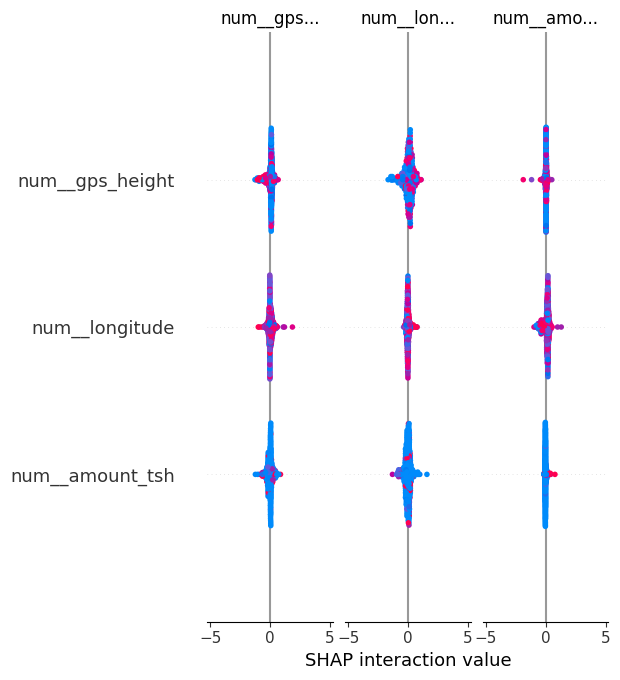

In [ ]:
shap.summary_plot(
    shap_values,
    X_sample,
    class_names=label_encoder.classes_
)

In [ ]:
print("Type:", type(shap_values))
print("Shape:", np.array(shap_values).shape)

Type: <class 'numpy.ndarray'>
Shape: (500, 2936, 3)


In [ ]:
print(best_lgbm.named_steps["model"].classes_)

['functional' 'functional needs repair' 'non functional']


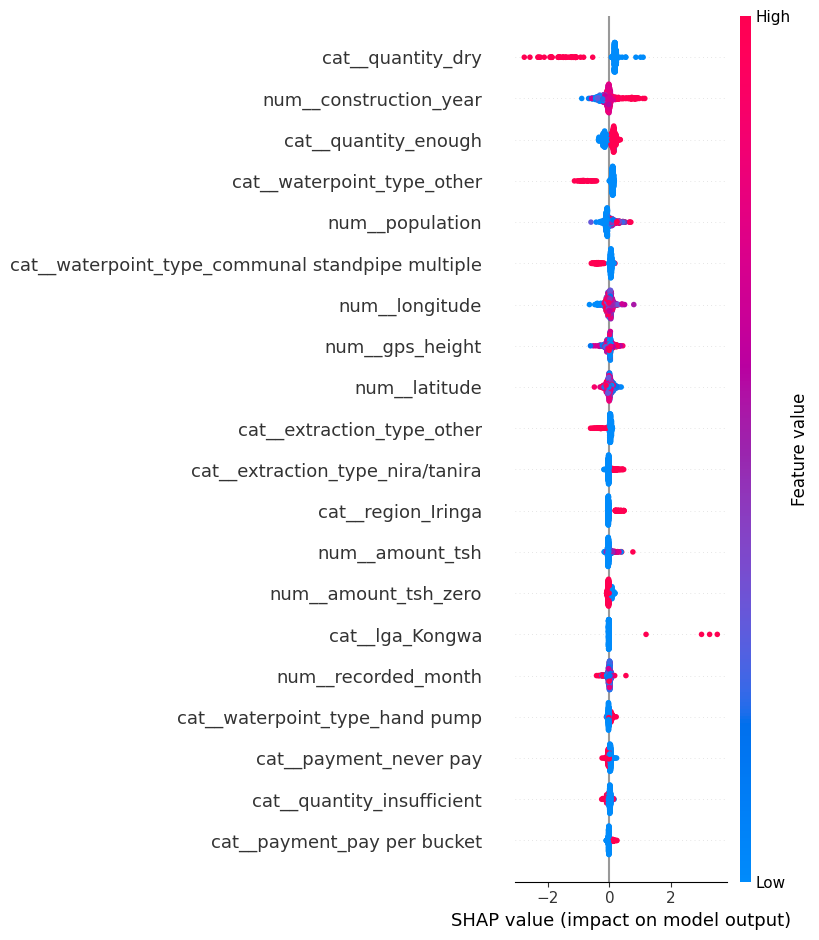

In [ ]:
shap.summary_plot(
    shap_values[:, :, 0],
    X_sample,
    max_display=20
)

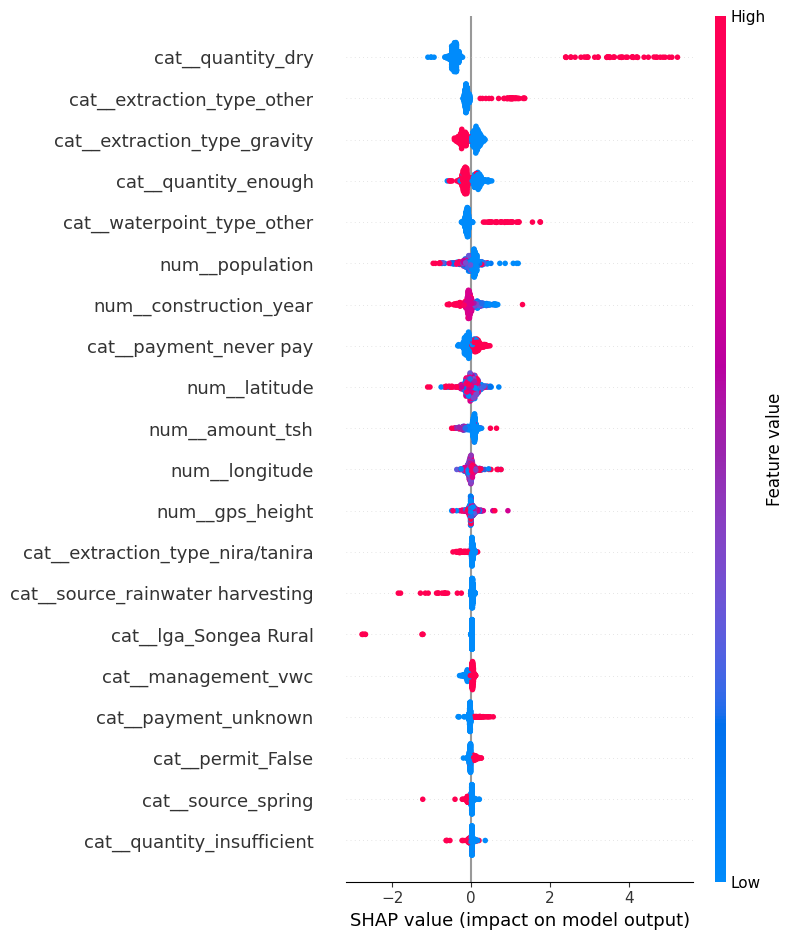

In [ ]:
shap.summary_plot(
    shap_values[:, :, 2],
    X_sample,
    max_display=20
)

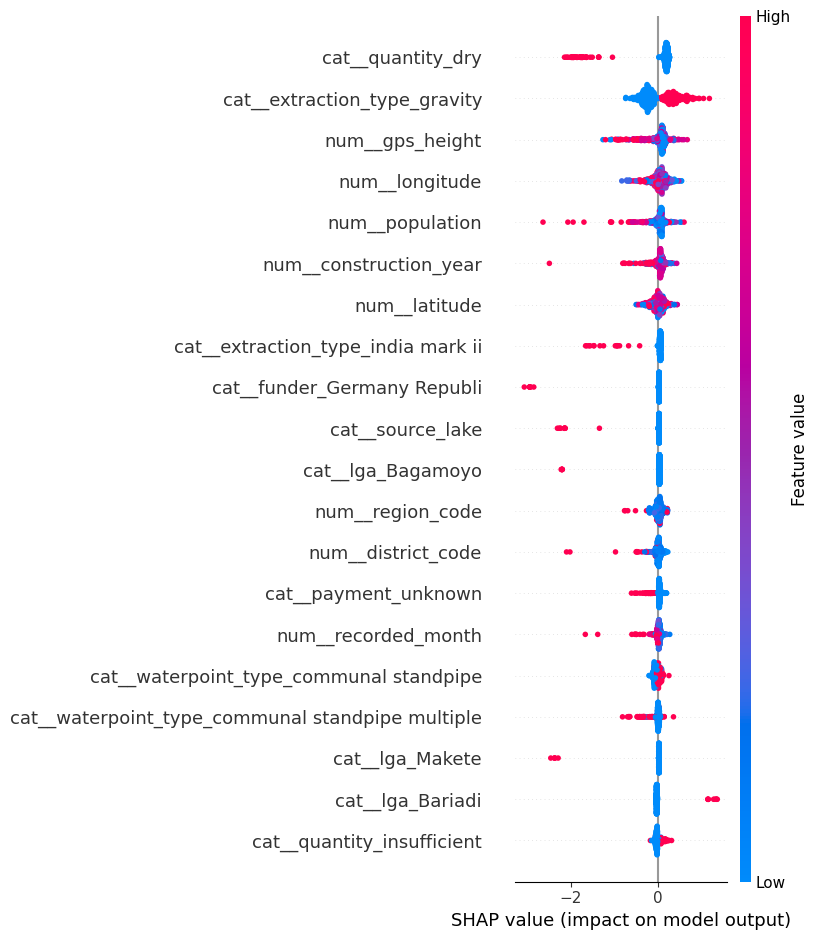

In [ ]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    max_display=20
)

In [ ]:
# Prédictions sur nos 500 observations
sample_predictions = best_lgbm.predict(X_sample_raw)

# Trouver une observation prédite "needs repair"
indices = np.where(
    sample_predictions == "functional needs repair"
)[0]

# Sélectionner la première
idx = indices[0]

print("Observation:", idx)
print("Prédiction:", sample_predictions[idx])
print("Statut réel:", y_val.loc[X_sample_raw.index[idx]])

Observation: 2
Prédiction: functional needs repair
Statut réel: functional


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


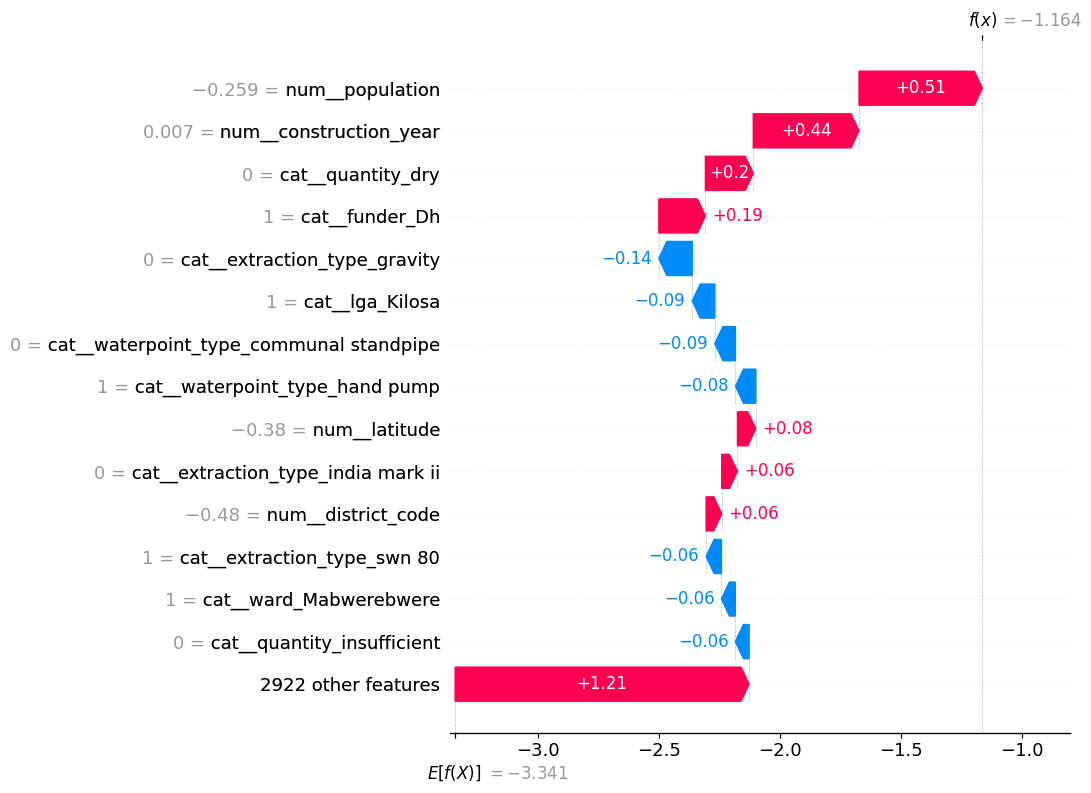

In [ ]:
explanation = shap.Explanation(
    values=shap_values[idx, :, 1],
    base_values=explainer.expected_value[1],
    data=X_sample.iloc[idx].values,
    feature_names=X_sample.columns
)

shap.plots.waterfall(explanation, max_display=15)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Water-Infrastructure-Intelligence")

print(PROJECT_DIR.exists())

True


In [ ]:
print("X_raw :", X_raw.shape)
print("y :", y.shape)

X_raw : (59400, 39)
y : (59400,)


In [ ]:
artifacts_dir = PROJECT_DIR / "artifacts"

if artifacts_dir.exists():
    for file in artifacts_dir.iterdir():
        print(file.name)
else:
    print("Le dossier artifacts n'existe pas.")

preprocessor.joblib
X_train_processed.joblib
X_val_processed.joblib
X_test_processed.joblib
y_train.joblib
y_val.joblib
test_ids.joblib


In [ ]:
import lightgbm
print(lightgbm.__version__)

4.6.0


In [ ]:
from lightgbm import LGBMClassifier

final_lgbm = LGBMClassifier(
    colsample_bytree=0.6571467271687763,
    learning_rate=0.13366880986028204,
    max_depth=-1,
    min_child_samples=11,
    n_estimators=543,
    num_leaves=49,
    class_weight="balanced",
    random_state=42,
    n_jobs=1,
    verbosity=-1
)

In [ ]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline(steps=[
    ("cleaner", WaterDataCleaner()),
    ("rare_grouper", RareCategoryGrouper(
        columns=["ward", "scheme_name", "installer", "funder"],
        min_frequency=10
    )),
    ("preprocessor", preprocessor),
    ("model", final_lgbm)
])

print(final_pipeline)

Pipeline(steps=[('cleaner', WaterDataCleaner()),
                ('rare_grouper',
                 RareCategoryGrouper(columns=['ward', 'scheme_name',
                                              'installer', 'funder'])),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x...
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                    

In [ ]:
final_pipeline.fit(X_raw, y)

Pipeline(steps=[('cleaner', WaterDataCleaner()),
                ('rare_grouper',
                 RareCategoryGrouper(columns=['ward', 'scheme_name',
                                              'installer', 'funder'])),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x...
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7c0c51b791d0>)])),
                ('model',
                 LGBMClassifier(class_weight='balanced',
                                colsample_bytree=0.6571467271687763,
                                learning_rate=0.13366880986028204,
                                min_child_samples=11, n_estimators=543,
                                n_jobs=1, num_leaves=49, random_state=42,
                                verbosity=-1))])

In [ ]:
import joblib

artifacts_dir = PROJECT_DIR / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_path = artifacts_dir / "best_lgbm_pipeline.joblib"

joblib.dump(final_pipeline, model_path)

print("Model saved successfully!")
print(model_path)

Model saved successfully!
/content/drive/MyDrive/Water-Infrastructure-Intelligence/artifacts/best_lgbm_pipeline.joblib


In [ ]:
loaded_pipeline = joblib.load(model_path)

print("Model loaded successfully!")
print(type(loaded_pipeline))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [ ]:
sample = X_val_raw.head(5)

predictions = loaded_pipeline.predict(sample)

print(predictions)

['non functional' 'functional' 'functional' 'functional' 'non functional']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [6]:
import sys
import sklearn
import lightgbm
import joblib
import numpy
import pandas

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)
print("LightGBM:", lightgbm.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.4
Pandas: 3.1.1
Scikit-learn: 1.6.1
LightGBM: 4.6.0
Joblib: 1.6.0


In [7]:
import numpy
import pandas

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)

NumPy: 2.5.4
Pandas: 3.1.1


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src.preprocessing import WaterDataCleaner, RareCategoryGrouper

import joblib

model = joblib.load("../artifacts/best_lgbm_pipeline.joblib")

In [3]:
import pandas as pd
model.predict(
    pd.read_csv("../data/raw/Test set values.csv").head()
)

c:\Users\21626\Desktop\Water-Infrastructure-Intelligence\.venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


array(['functional', 'functional needs repair', 'functional',
       'non functional', 'functional'], dtype=object)

In [4]:
predictions = model.predict(
    pd.read_csv("../data/raw/Test set values.csv")
)

print(pd.Series(predictions).value_counts())

c:\Users\21626\Desktop\Water-Infrastructure-Intelligence\.venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


functional                 7304
non functional             5431
functional needs repair    2115
Name: count, dtype: int64


In [9]:
print("Model class:", type(model))
print("\nPipeline steps:")

for name, step in model.named_steps.items():
    print(name, "→", type(step), "| Module:", type(step).__module__)

print("\nCustom transformers:")
print(WaterDataCleaner.__module__)
print(RareCategoryGrouper.__module__)

Model class: <class 'sklearn.pipeline.Pipeline'>

Pipeline steps:
cleaner → <class 'src.preprocessing.WaterDataCleaner'> | Module: src.preprocessing
rare_grouper → <class 'src.preprocessing.RareCategoryGrouper'> | Module: src.preprocessing
preprocessor → <class 'sklearn.compose._column_transformer.ColumnTransformer'> | Module: sklearn.compose._column_transformer
model → <class 'lightgbm.sklearn.LGBMClassifier'> | Module: lightgbm.sklearn

Custom transformers:
src.preprocessing
src.preprocessing
